**Pasul 1.** Citirea bibliotecilor necesare și vizualizarea informației despre mapa cu imagini

In [140]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pathlib
import os
from tqdm import tqdm

In [141]:
len(os.listdir("satelite/cloudy"))

1500

In [142]:
len(os.listdir("satelite/desert"))

1131

In [143]:
len(os.listdir("satelite/green_area"))

1500

In [144]:
len(os.listdir("satelite/water"))

1500

In [145]:
DataPath = pathlib.Path("satelite")
all_paths = DataPath.glob("*/*.jpg")
all_paths

<generator object Path.glob at 0x7f1a0582b350>

**Pasul 2.**  Citirea primelor 10 imagini din fișie

In [146]:
all_paths = list(all_paths)
print(len(all_paths))
all_paths[:10]

5631


[PosixPath('satelite/cloudy/train_10021.jpg'),
 PosixPath('satelite/cloudy/train_10043.jpg'),
 PosixPath('satelite/cloudy/train_10070.jpg'),
 PosixPath('satelite/cloudy/train_10081.jpg'),
 PosixPath('satelite/cloudy/train_10096.jpg'),
 PosixPath('satelite/cloudy/train_101.jpg'),
 PosixPath('satelite/cloudy/train_10128.jpg'),
 PosixPath('satelite/cloudy/train_10166.jpg'),
 PosixPath('satelite/cloudy/train_10173.jpg'),
 PosixPath('satelite/cloudy/train_10177.jpg')]

In [147]:
all_paths = list(map(lambda x : str(x), all_paths))
all_paths[:10]

['satelite/cloudy/train_10021.jpg',
 'satelite/cloudy/train_10043.jpg',
 'satelite/cloudy/train_10070.jpg',
 'satelite/cloudy/train_10081.jpg',
 'satelite/cloudy/train_10096.jpg',
 'satelite/cloudy/train_101.jpg',
 'satelite/cloudy/train_10128.jpg',
 'satelite/cloudy/train_10166.jpg',
 'satelite/cloudy/train_10173.jpg',
 'satelite/cloudy/train_10177.jpg']

**Pasul 3.** Amestecarea imaginilor în fișier cu scopul evitării antrenării rețelei doar pe un anumit
tip de imagini :

In [148]:
from random import shuffle

shuffle(all_paths)
print(len(all_paths))
all_paths[:10]

5631


['satelite/desert/desert(425).jpg',
 'satelite/cloudy/train_902.jpg',
 'satelite/desert/desert(255).jpg',
 'satelite/desert/desert(758).jpg',
 'satelite/desert/desert(677).jpg',
 'satelite/desert/desert(160).jpg',
 'satelite/green_area/Forest_330.jpg',
 'satelite/cloudy/train_29996.jpg',
 'satelite/water/SeaLake_1093.jpg',
 'satelite/desert/desert(875).jpg']

**Pasul 4.** Decodarea imaginilor :

In [149]:
def FilterValidImages(all_paths):
    new_all_paths = []
    for path in tqdm(all_paths):
        try:
            image = tf.io.read_file(path)
            image = tf.io.decode_jpeg(image, channels = 3)
        except:
            continue
        new_all_paths.append(path)
    return new_all_paths

all_paths = FilterValidImages(all_paths)
all_paths[:10]


00%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5631/5631 [00:03<00:00, 1678.24it/s]

['satelite/desert/desert(425).jpg',
 'satelite/cloudy/train_902.jpg',
 'satelite/desert/desert(255).jpg',
 'satelite/desert/desert(758).jpg',
 'satelite/desert/desert(677).jpg',
 'satelite/desert/desert(160).jpg',
 'satelite/green_area/Forest_330.jpg',
 'satelite/cloudy/train_29996.jpg',
 'satelite/water/SeaLake_1093.jpg',
 'satelite/desert/desert(875).jpg']

**Pasul 5.** Obținerea etichetelor și transformarea lor în 0 și 1

In [150]:
def get_label(image_path):
    return image_path.split("/")[-2]

all_labels = list(map(lambda x : get_label(x), all_paths))
all_labels[:10]

['desert',
 'cloudy',
 'desert',
 'desert',
 'desert',
 'desert',
 'green_area',
 'cloudy',
 'water',
 'desert']

In [151]:
# from sklearn.preprocessing import LabelEncoder

Le = LabelEncoder()
all_labels = Le.fit_transform(all_labels)

all_labels[:10]

array([1, 0, 1, 1, 1, 1, 2, 0, 3, 1])

In [152]:
# print encodings
label_mapping = dict(zip(Le.classes_, Le.transform(Le.classes_)))
for label, encoded in label_mapping.items():
    print(f"{encoded} -> {label}")

0 -> cloudy
1 -> desert
2 -> green_area
3 -> water


**Pasul 6.** Crearea setului de antrenament

In [153]:
from sklearn.model_selection import train_test_split
Train_paths, Val_paths, Train_labels, Val_labels = train_test_split(all_paths, all_labels)

In [154]:
Train_paths[:10], Train_labels[:10]

(['satelite/cloudy/train_5294.jpg',
  'satelite/desert/desert(15).jpg',
  'satelite/cloudy/train_15077.jpg',
  'satelite/cloudy/train_10225.jpg',
  'satelite/cloudy/train_38957.jpg',
  'satelite/green_area/Forest_2171.jpg',
  'satelite/cloudy/train_7791.jpg',
  'satelite/desert/desert(760).jpg',
  'satelite/cloudy/train_10581.jpg',
  'satelite/water/SeaLake_1939.jpg'],
 array([0, 1, 0, 0, 0, 2, 0, 1, 0, 3]))

In [155]:
def loadImage(image, label):
    image = tf.io.read_file(image)
    image = tf.io.decode_jpeg(image, channels=3)
    
    # Check if image is loaded correctly
    if tf.reduce_all(tf.equal(image, 0)):  # If image is all zeros (black)
        print(f"Warning: Image {image} seems to be empty or black.")
    
    return image, label

In [156]:
# define image size and batch size
IMG_SIZE = 128
BATCH_SIZE = 128

def resize(image):
    return tf.image.resize(image, [224, 224])
    
def data_augmentation(image):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    return image

In [157]:
# Create a Tensorflow Data Object
AUTOTUNE = tf.data.experimental.AUTOTUNE

def resize(image):
    return tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

def data_augmentation(image):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    return image



def get_dataset(paths, labels, train=True):
    image_paths = tf.convert_to_tensor(paths)
    labels = tf.convert_to_tensor(labels)

    image_dataset = tf.data.Dataset.from_tensor_slices(image_paths)
    label_dataset = tf.data.Dataset.from_tensor_slices(labels)

    dataset = tf.data.Dataset.zip((image_dataset, label_dataset))
    dataset = dataset.map(lambda image, label: loadImage(image, label))
    dataset = dataset.map(lambda image, label: (resize(image), label), num_parallel_calls=AUTOTUNE)
    dataset = dataset.shuffle(1000)
    dataset = dataset.batch(BATCH_SIZE)

    if train:
        dataset = dataset.map(lambda image, label: (data_augmentation(image), label), num_parallel_calls=AUTOTUNE)
        dataset = dataset.repeat()

    return dataset

In [158]:
# Creating Train Dataset object and Verifying it
%time train_dataset = get_dataset(Train_paths, Train_labels)

train_dataset

image, label = next(iter(train_dataset))
print(image.shape)
print(label.shape)

CPU times: user 177 ms, sys: 5.74 ms, total: 183 ms
Wall time: 180 ms
(128, 128, 128, 3)
(128,)


**Pasul 7.** Vizualizarea a câte un exemplu din fiecare clasă : cat, dog (din setul de antrenament) pentru a ne asigura că este citit corect 

In [159]:
import matplotlib.pyplot as plt
import tensorflow as tf

def display_image_grid(dataset, rows=3, cols=3):
    """
    Displays a grid of images from the provided dataset.
    
    Parameters:
    dataset (iterable): The dataset from which images will be taken.
    rows (int): Number of rows in the grid.
    cols (int): Number of columns in the grid.
    """
    # Create a figure to display the images
    fig, axes = plt.subplots(rows, cols, figsize=(10, 8))

    # Loop through the rows and columns to display images
    for i in range(rows):
        for j in range(cols):
            ax = axes[i, j]  # Accessing each subplot axis
            image, label = next(iter(dataset))  # Get next image and label

            # Convert the image to NumPy array if it's an EagerTensor
            image = image[0].numpy()  # If the image is a batch, we select the first one

            # Get min and max values
            image_min = image.min()
            image_max = image.max()

            # Avoid division by zero (constant image)
            if image_max == image_min:
                print(f"Image {i * cols + j} is constant, skipping scaling.")
                image = image / 255.0  # Normalize to [0, 1]
            else:
                # Normalize the image to [0, 1]
                image = (image - image_min) / (image_max - image_min)

            ax.imshow(image)  # Display the image
            ax.set_title(f"Label: {Le.inverse_transform(label)[0]}")  # Set title with label
            ax.axis('off')  # Hide axes

    plt.tight_layout()  # Adjust spacing between images
    plt.show()

# Example call:
# display_image_grid(train_dataset)


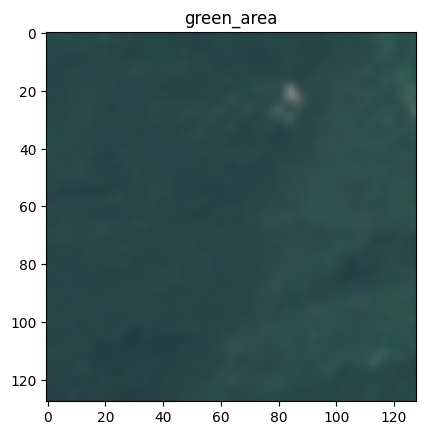

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0002771016..-0.0002771016].


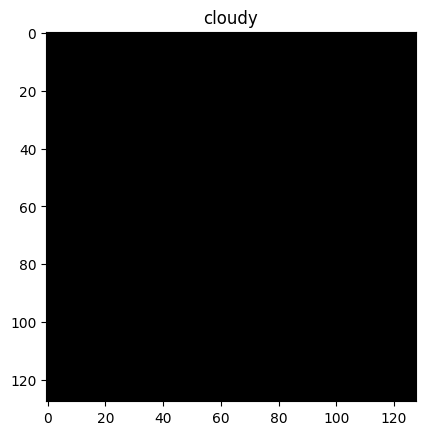

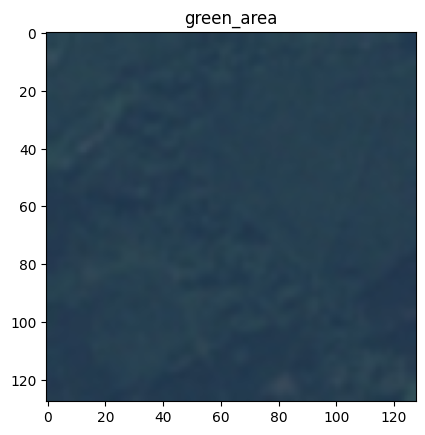

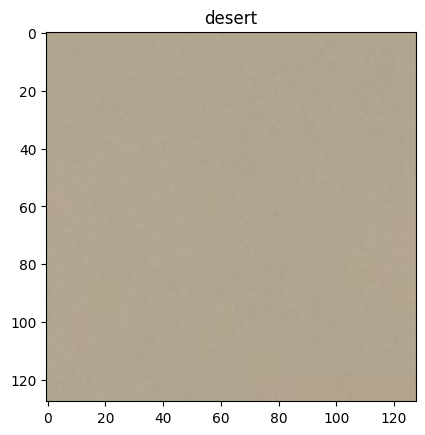

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.255576e-05..-4.255576e-05].


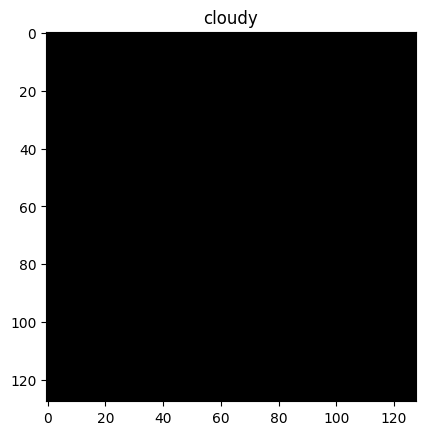

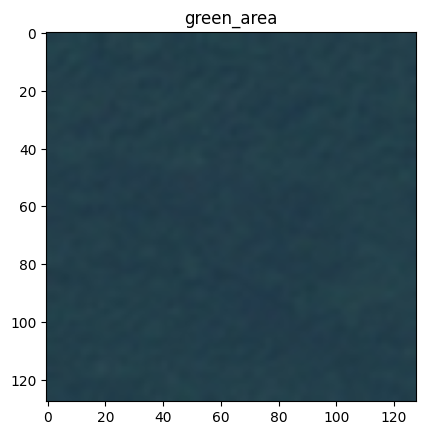

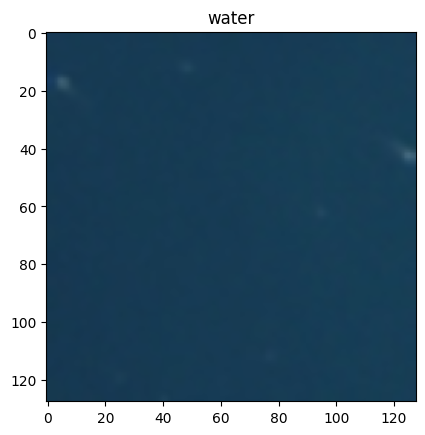

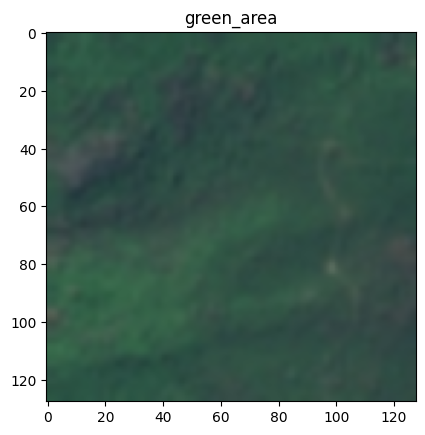

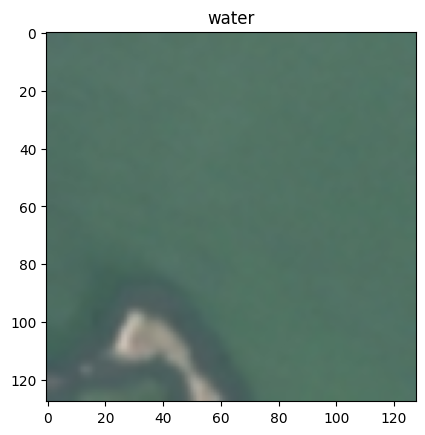

In [160]:
# View a sample Taining image
# print(Le.inverse_transform(label)[0])
# plt.imshow((image[0].numpy() / 255))

# display_image_grid(train_dataset)


for i in range(9):
    image, label = next(iter(train_dataset))
    plt.imshow(image[0].numpy() / 255)
    plt.title(Le.inverse_transform(label)[0])
    plt.show()



Image 0 - Min: -3.144890069961548e-05, Max: -3.144890069961548e-05
Image 0 appears constant - Min: -3.144890069961548e-05, Max: -3.144890069961548e-05
Image 0 Post-Normalization - Min: 1.0, Max: 1.0


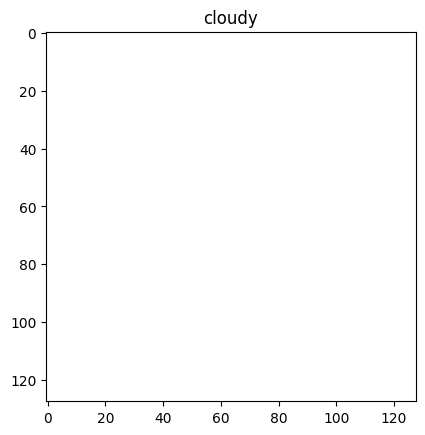

Image 1 - Min: 90.58121490478516, Max: 186.33120727539062
Image 1 Post-Normalization - Min: 0.3552204370498657, Max: 0.7307106256484985


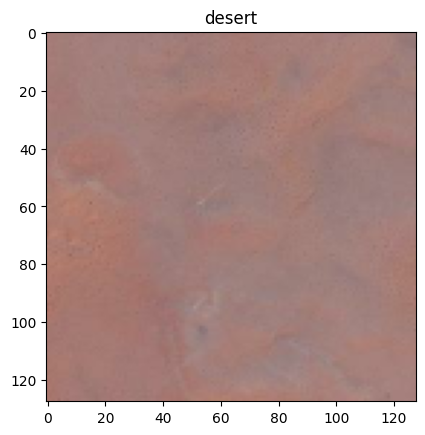

Image 2 - Min: 26.347089767456055, Max: 105.97209167480469
Image 2 Post-Normalization - Min: 0.10332191735506058, Max: 0.4155768156051636


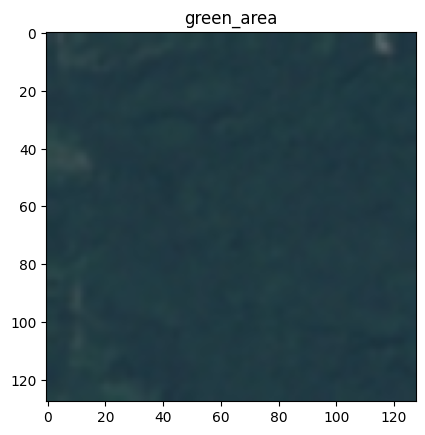

Image 3 - Min: -0.036177873611450195, Max: -0.036177873611450195
Image 3 appears constant - Min: -0.036177873611450195, Max: -0.036177873611450195
Image 3 Post-Normalization - Min: 1.0, Max: 1.0


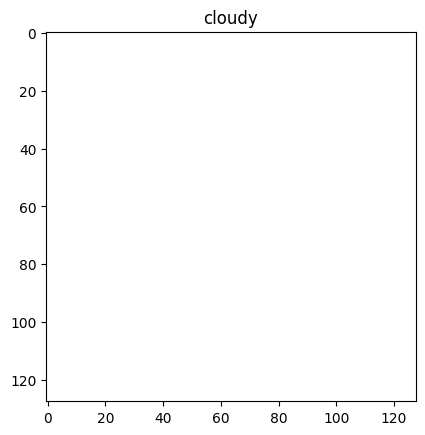

Image 4 - Min: 0.06578541547060013, Max: 0.06578541547060013
Image 4 appears constant - Min: 0.06578541547060013, Max: 0.06578541547060013
Image 4 Post-Normalization - Min: 1.0, Max: 1.0


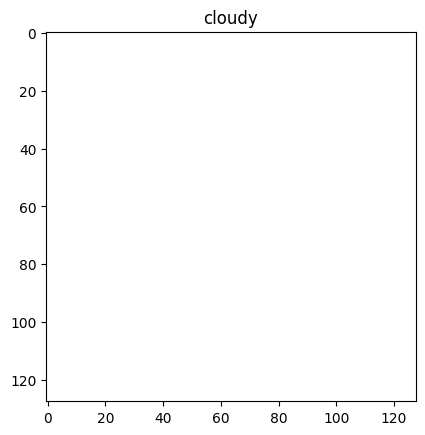

Image 5 - Min: 35.6719970703125, Max: 98.1094970703125
Image 5 Post-Normalization - Min: 0.1398901790380478, Max: 0.3847431242465973


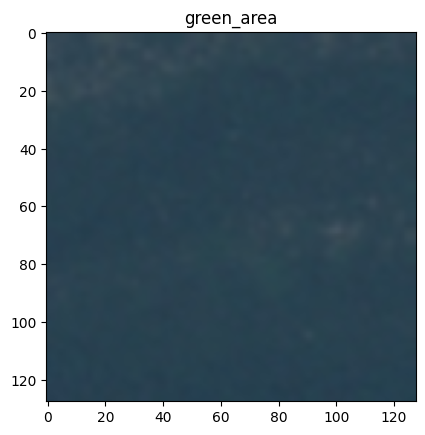

Image 6 - Min: 60.2875862121582, Max: 205.03758239746094
Image 6 Post-Normalization - Min: 0.23642191290855408, Max: 0.804068922996521


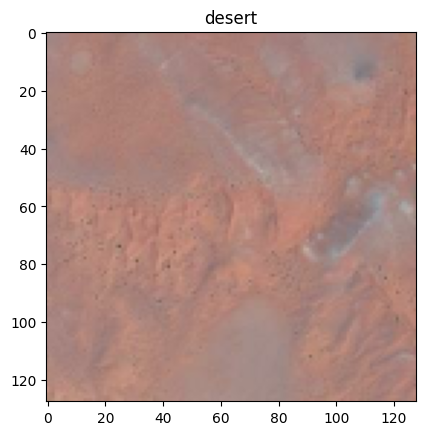

Image 7 - Min: -0.07303988933563232, Max: -0.07303988933563232
Image 7 appears constant - Min: -0.07303988933563232, Max: -0.07303988933563232
Image 7 Post-Normalization - Min: 1.0, Max: 1.0


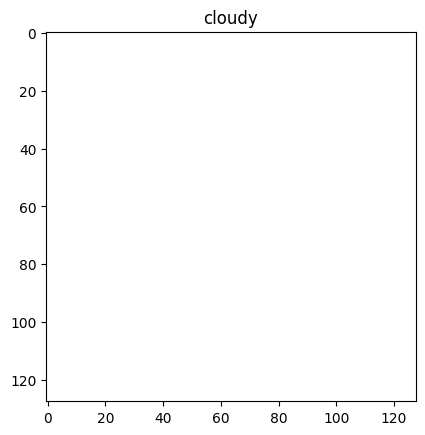

Image 8 - Min: 109.94558715820312, Max: 232.44558715820312
Image 8 Post-Normalization - Min: 0.4311591684818268, Max: 0.911551296710968


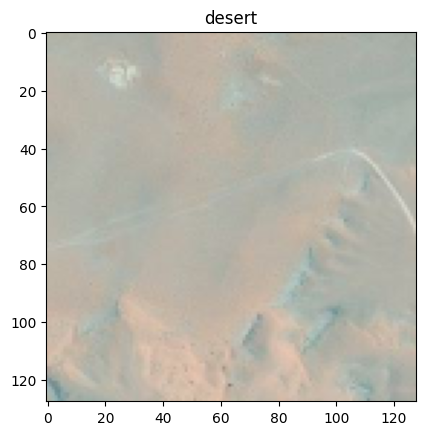

In [161]:
for i in range(9):
    image, label = next(iter(train_dataset))

    # Convert image to NumPy array
    image = image[0].numpy()

    # Debugging: Print min and max of image before normalization
    print(f"Image {i} - Min: {image.min()}, Max: {image.max()}")

    # Check if the image is within the expected range
    if image.min() == image.max():
        print(f"Image {i} appears constant - Min: {image.min()}, Max: {image.max()}")
        # You might want to handle constant images here, e.g., display a default value
        image = tf.ones_like(image).numpy()  # Placeholder (white image)
    else:
        # Normalize the image to [0, 1]
        image = image / 255.0

    # Debugging: Print image stats after normalization
    print(f"Image {i} Post-Normalization - Min: {image.min()}, Max: {image.max()}")

    # Display the image
    plt.imshow(image)
    plt.title(Le.inverse_transform(label)[0])
    plt.show()


In [162]:
%time val_dataset = get_dataset(Val_paths, Val_labels, train = False)

image, label = next(iter(val_dataset))
print(image.shape)
print(label.shape)

CPU times: user 60.5 ms, sys: 4.17 ms, total: 64.7 ms
Wall time: 60.5 ms
(128, 128, 128, 3)
(128,)


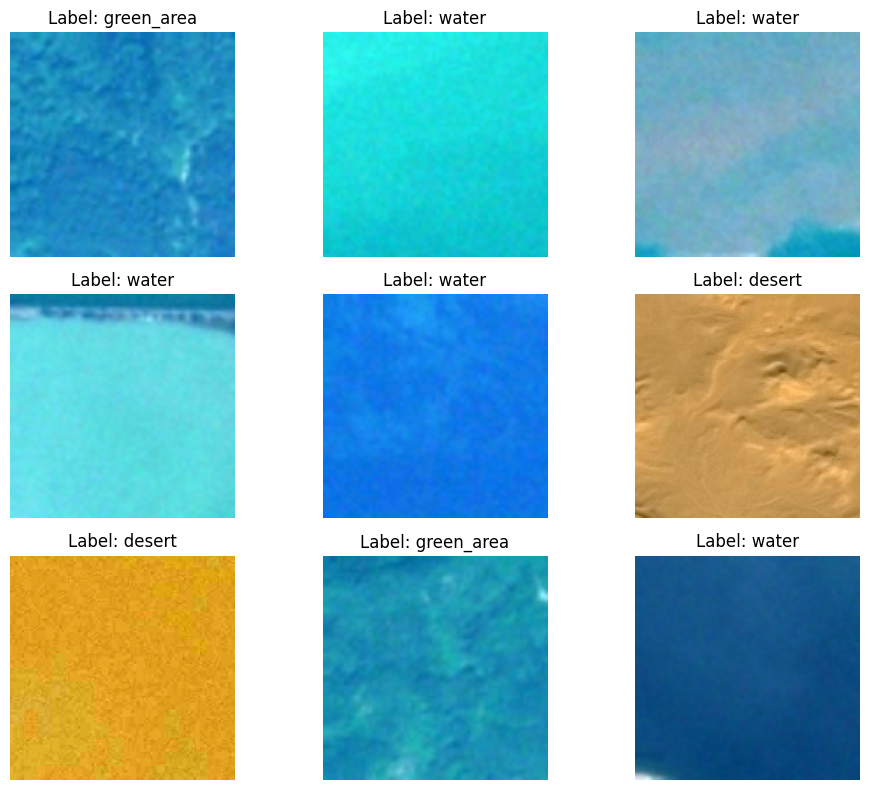

In [163]:
# View a sample training image
# print(Le.inverse_transform(label)[0])
# plt.imshow((image[0].numpy() / 255))

display_image_grid(val_dataset)